# 4M-21 Caption Forgetting — Baseline vs LoRA (run 15: r8/selfattn/depth)

**Goal**: visualise whether depth fine-tuning causes the model to forget captioning.

**Grid**: N rows × 4 columns
  - Col 1: RGB image (from COCO val2017)
  - Col 2: GT captions (from `captions_val2017.json`, one shown per image)
  - Col 3: Baseline caption (4M-21 XL, no LoRA)
  - Col 4: LoRA caption (run 15: rank=8, selfattn, trained on NYUv2 depth)

**Metrics** (official COCO captioning evaluation via `pycocoevalcap`):
  - CIDEr   consensus-based image description evaluation   ↑ higher is better
  - BLEU@4  4-gram precision                               ↑ higher is better
  - ROUGE_L longest common subsequence                     ↑ higher is better
  - METEOR  unigram F-score with synonyms                  ↑ higher is better

**Dataset**: COCO val2017 — 5000 images, 5 GT captions each
  Images  : `/scratch-shared/tesr125338/coco/val2017/`
  Captions: `/scratch-shared/tesr125338/coco/annotations/captions_val2017.json`

**Run as script** (headless):
  python notebooks/viz_caption_forgetting.py

**Run in Jupyter** on Snellius:
  Open this file in JupyterLab → Run All Cells

## Config — edit paths here

In [4]:
import os, sys

REPO_ROOT = os.path.expanduser('~/4m-peft')
os.chdir(REPO_ROOT)
sys.path.insert(0, os.path.join(REPO_ROOT, 'ml-4m'))

# pip_packages installed on scratch (pycocoevalcap, pycocotools, nltk)
PIP_PACKAGES = '/scratch-shared/tesr125338/pip_packages'
NLTK_DATA    = '/scratch-shared/tesr125338/nltk_data'
if PIP_PACKAGES not in sys.path:
    sys.path.append(PIP_PACKAGES)   # append: conda numpy stays first

import nltk
nltk.data.path.append(NLTK_DATA)

# ── Paths ─────────────────────────────────────────────────────────────────────
COCO_ROOT    = '/scratch-shared/tesr125338/coco/val2017'
COCO_ANN     = '/scratch-shared/tesr125338/coco/annotations/captions_val2017.json'
LORA_WEIGHTS = '/scratch-shared/tesr125338/output/depth/nyu_labeled_r8_selfattn_drop005/lora_weights-best.pth'
HF_CACHE     = '/scratch-shared/tesr125338/hf_cache'
FIGURES_DIR  = os.path.join(REPO_ROOT, 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)

# ── LoRA config (must match training run 15) ──────────────────────────────────
LORA_RANK    = 8
LORA_MODULES = 'selfattn'

# ── Evaluation ────────────────────────────────────────────────────────────────
N_VIZ        = 10      # rows in the visual grid
N_METRICS    = 200     # images for CIDEr/BLEU (more = more reliable IDF weights)
SEED         = 42

# ── Caption generation params (same as eval_caption_forgetting.py) ─────────────
CAPTION_GEN_PARAMS = {
    'tokens_per_target':       64,
    'autoregression_scheme':   'autoregressive',
    'decoding_steps':          64,
    'token_decoding_schedule': 'linear',
    'temp':                    0.01,   # near-greedy for deterministic eval
    'temp_schedule':           'constant',
    'cfg_scale':               2.0,
    'cfg_schedule':            'constant',
}

# ── 4M model IDs ──────────────────────────────────────────────────────────────
FM_MODEL      = 'EPFL-VILAB/4M-21_XL'
TOK_TEXT_PATH = os.path.join(REPO_ROOT,
    'ml-4m/fourm/utils/tokenizer/trained/text_tokenizer_4m_wordpiece_30k.json')

import torch
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE  = torch.bfloat16
print(f'Device: {DEVICE}  |  dtype: {DTYPE}')
assert os.path.exists(LORA_WEIGHTS), f'LoRA weights not found: {LORA_WEIGHTS}'
assert os.path.exists(COCO_ANN),     f'COCO annotations not found: {COCO_ANN}'
print(f'LoRA : {LORA_WEIGHTS}  ✓')
print(f'COCO : {COCO_ANN}  ✓')

Device: cuda  |  dtype: torch.bfloat16
LoRA : /scratch-shared/tesr125338/output/depth/nyu_labeled_r8_selfattn_drop005/lora_weights-best.pth  ✓
COCO : /scratch-shared/tesr125338/coco/annotations/captions_val2017.json  ✓


## Imports

In [5]:
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import textwrap
from pathlib import Path
from PIL import Image
from tokenizers import Tokenizer
from torchvision.transforms.functional import center_crop
from tqdm import tqdm

from fourm.models.fm import FM
from fourm.models.generate import (
    GenerationSampler, build_chained_generation_schedules,
    init_empty_target_modality, init_full_input_modality,
)
from fourm.data.modality_info import MODALITY_INFO
from fourm.data.modality_transforms import RGBTransform
from fourm.models.lora_utils import inject_trainable_LoRA, get_LoRA_module_names

print('Imports OK')

/home/fcolasurdo/.conda/envs/4m-peft/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK


## Helper functions
Exact same generation and decoding as `eval_caption_forgetting.py`.

In [6]:
def load_rgb_tensor(image_path):
    """RGB image → (1,3,224,224) ImageNet-normalised tensor."""
    rgb_transform = RGBTransform(imagenet_default_mean_and_std=True)
    img_pil = rgb_transform.load(str(image_path))
    img_pil = rgb_transform.preprocess(img_pil)
    s       = min(img_pil.size)
    img_pil = center_crop(img_pil, (s, s)).resize((224, 224), Image.BILINEAR)
    return rgb_transform.postprocess(img_pil).unsqueeze(0).to(device=DEVICE, dtype=DTYPE)


def load_rgb_display(image_path):
    """RGB → (224,224,3) uint8 numpy for display."""
    img = Image.open(image_path).convert('RGB')
    s   = min(img.size)
    img = center_crop(img, (s, s)).resize((224, 224), Image.BILINEAR)
    return np.array(img)


def generate_caption(sampler, tok_text, rgb_tensor, seed):
    """RGB tensor → raw output dict with generated caption tokens."""
    ntoks    = CAPTION_GEN_PARAMS['tokens_per_target']
    schedule = build_chained_generation_schedules(
        cond_domains            = ['rgb@224'],
        target_domains          = ['caption'],
        tokens_per_target       = [ntoks],
        autoregression_schemes  = [CAPTION_GEN_PARAMS['autoregression_scheme']],
        decoding_steps          = [CAPTION_GEN_PARAMS['decoding_steps']],
        token_decoding_schedules= [CAPTION_GEN_PARAMS['token_decoding_schedule']],
        temps                   = [CAPTION_GEN_PARAMS['temp']],
        temp_schedules          = [CAPTION_GEN_PARAMS['temp_schedule']],
        cfg_scales              = [CAPTION_GEN_PARAMS['cfg_scale']],
        cfg_schedules           = [CAPTION_GEN_PARAMS['cfg_schedule']],
        cfg_grow_conditioning   = True,
    )
    eos_id = tok_text.token_to_id('[EOS]')
    sd = {'rgb@224': {'tensor': rgb_tensor}}
    sd = init_full_input_modality(sd, MODALITY_INFO, 'rgb@224', DEVICE, eos_id=eos_id)
    sd = init_empty_target_modality(sd, MODALITY_INFO, 'caption', 1, ntoks, DEVICE)
    return sampler.generate(sd, schedule, text_tokenizer=tok_text, verbose=False, seed=seed)


def decode_caption_string(out_dict, tok_text):
    """Generated output dict → plain text string."""
    tokens = out_dict['caption']['tensor']
    if tokens.ndim > 1:
        tokens = tokens[0]
    token_ids = tokens.cpu().tolist()
    eos_id = tok_text.token_to_id('[EOS]')
    if eos_id in token_ids:
        token_ids = token_ids[:token_ids.index(eos_id)]
    token_ids = [t for t in token_ids if t > 0]
    if not token_ids:
        return ''
    return tok_text.decode(token_ids, skip_special_tokens=True).strip()


print('Helper functions defined.')

Helper functions defined.


## Load COCO val2017 samples and GT captions

In [7]:
tok_text = Tokenizer.from_file(TOK_TEXT_PATH)
print(f'Text tokenizer: vocab={tok_text.get_vocab_size()}')

with open(COCO_ANN) as f:
    coco_data = json.load(f)

# image_id → file path
id2path = {img['id']: os.path.join(COCO_ROOT, img['file_name'])
           for img in coco_data['images']}

# image_id → list of GT captions
id2captions = {}
for ann in coco_data['annotations']:
    id2captions.setdefault(ann['image_id'], []).append(ann['caption'])

# Keep only images with file on disk
all_samples = [
    {'image_id': iid, 'path': path}
    for iid, path in sorted(id2path.items())
    if os.path.exists(path)
]
print(f'COCO val2017 samples on disk: {len(all_samples)}')

# Fixed subset for reproducibility
rng = np.random.default_rng(SEED)
indices = rng.choice(len(all_samples), size=max(N_VIZ, N_METRICS), replace=False)
indices.sort()
viz_samples     = [all_samples[i] for i in indices[:N_VIZ]]
metrics_samples = [all_samples[i] for i in indices[:N_METRICS]]
print(f'Viz samples: {N_VIZ}  |  Metrics samples: {N_METRICS}')

Text tokenizer: vocab=30000
COCO val2017 samples on disk: 5000
Viz samples: 10  |  Metrics samples: 200


## Phase 1 — Baseline inference

In [8]:
print('Loading baseline FM ...')
fm = FM.from_pretrained(FM_MODEL, cache_dir=HF_CACHE)
fm = fm.to(device=DEVICE, dtype=DTYPE).eval()
sampler = GenerationSampler(fm)
print(f'FM ready ({sum(p.numel() for p in fm.parameters())/1e6:.0f}M params)')

captions_baseline = {}    # image_id → generated caption string
for s in tqdm(metrics_samples, desc='Baseline'):
    try:
        rgb_t = load_rgb_tensor(s['path'])
        with torch.no_grad():
            out = generate_caption(sampler, tok_text, rgb_t, seed=SEED)
        captions_baseline[s['image_id']] = decode_caption_string(out, tok_text)
    except Exception as e:
        captions_baseline[s['image_id']] = ''
        print(f'  skip {s["image_id"]}: {e}')

del fm, sampler
torch.cuda.empty_cache()
print(f'Baseline done. {len(captions_baseline)} captions generated.')

Loading baseline FM ...
FM ready (4518M params)


Baseline: 100%|██████████| 200/200 [01:19<00:00,  2.51it/s]

Baseline done. 200 captions generated.


## Phase 2 — LoRA inference

In [9]:
print('Loading LoRA FM ...')
fm = FM.from_pretrained(FM_MODEL, cache_dir=HF_CACHE)
target_mods = get_LoRA_module_names(LORA_MODULES)
inject_trainable_LoRA(fm, rank=LORA_RANK, scale=1.0, target_replace_modules=target_mods)
lora_sd = torch.load(LORA_WEIGHTS, map_location='cpu')
missing, unexpected = fm.load_state_dict(lora_sd, strict=False)
print(f'  Loaded {len(lora_sd)} LoRA tensors (missing={len(missing)}, unexpected={len(unexpected)})')
fm = fm.to(device=DEVICE, dtype=DTYPE).eval()
sampler = GenerationSampler(fm)

captions_lora = {}        # image_id → generated caption string
for s in tqdm(metrics_samples, desc='LoRA r8/selfattn'):
    try:
        rgb_t = load_rgb_tensor(s['path'])
        with torch.no_grad():
            out = generate_caption(sampler, tok_text, rgb_t, seed=SEED)
        captions_lora[s['image_id']] = decode_caption_string(out, tok_text)
    except Exception as e:
        captions_lora[s['image_id']] = ''
        print(f'  skip {s["image_id"]}: {e}')

del fm, sampler
torch.cuda.empty_cache()
print(f'LoRA done. {len(captions_lora)} captions generated.')

Loading LoRA FM ...
  Loaded 192 LoRA tensors (missing=733, unexpected=0)


LoRA r8/selfattn: 100%|██████████| 200/200 [01:35<00:00,  2.09it/s]

LoRA done. 200 captions generated.


## Metrics — official COCO evaluation (pycocoevalcap)
CIDEr, BLEU@4, ROUGE_L, METEOR computed with the official COCO toolkit.
Same library used by the COCO leaderboard — not invented formulas.

In [10]:
from pycocotools.coco import COCO
from pycocoevalcap.eval import COCOEvalCap

eval_ids = list(captions_baseline.keys())

def run_coco_eval(captions_dict, ann_file, image_ids, label):
    predictions = [{'image_id': iid, 'caption': cap}
                   for iid, cap in captions_dict.items()
                   if iid in set(image_ids)]
    coco_gt   = COCO(ann_file)
    coco_dt   = coco_gt.loadRes(predictions)
    evaluator = COCOEvalCap(coco_gt, coco_dt)
    evaluator.params['image_id'] = image_ids
    evaluator.evaluate()
    print(f'\n[{label}]')
    for k, v in evaluator.eval.items():
        print(f'  {k:<12}: {v:.4f}')
    return evaluator.eval

print('Running COCO evaluation ...\n')
metrics_base = run_coco_eval(captions_baseline, COCO_ANN, eval_ids, 'Baseline')
metrics_lora = run_coco_eval(captions_lora,     COCO_ANN, eval_ids, 'LoRA r8/selfattn')

print(f'\n{"Metric":<12} {"Baseline":>12} {"LoRA r8":>12} {"Δ":>10}')
print('─' * 50)
for k in ['CIDEr', 'Bleu_4', 'ROUGE_L', 'METEOR']:
    b = metrics_base.get(k, float('nan'))
    l = metrics_lora.get(k, float('nan'))
    arrow = '↓ forget' if (l - b) < -0.02 else ('≈ ok' if abs(l - b) < 0.02 else '↑')
    print(f'{k:<12} {b:>12.4f} {l:>12.4f} {l-b:>+10.4f}  {arrow}')
print(f'\nN = {len(eval_ids)} images  |  toolkit: pycocoevalcap (official COCO)')

Running COCO evaluation ...

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
tokenization...


PTBTokenizer tokenized 12295 tokens at 72757.03 tokens per second.
May 09, 2026 11:03:08 AM edu.stanford.nlp.process.PTBLexer next
PTBTokenizer tokenized 1279 tokens at 8000.18 tokens per second.


setting up scorers...
Progress: 384.5M / 384.5M (100.0%)
Extracting stanford-corenlp-3.6.0 ...
Done.
computing Bleu score...
{'testlen': 1027, 'reflen': 1735, 'guess': [1027, 827, 633, 456], 'correct': [407, 93, 20, 6]}
ratio: 0.5919308357345292
Bleu_1: 0.199
Bleu_2: 0.106
Bleu_3: 0.056
Bleu_4: 0.033
computing METEOR score...
METEOR: 0.082
computing Rouge score...
ROUGE_L: 0.210
computing CIDEr score...
CIDEr: 0.194
computing SPICE score...


Exception in thread "main" java.lang.ExceptionInInitializerError
	at edu.anu.spice.SpiceParser.<init>(SpiceParser.java:178)
	at edu.anu.spice.SpiceScorer.scoreBatch(SpiceScorer.java:70)
	at edu.anu.spice.SpiceScorer.main(SpiceScorer.java:60)
Caused by: java.lang.reflect.InaccessibleObjectException: Unable to make field private final byte[] java.lang.String.value accessible: module java.base does not "opens java.lang" to unnamed module @1ed6993a
	at java.base/java.lang.reflect.AccessibleObject.throwInaccessibleObjectException(AccessibleObject.java:391)
	at java.base/java.lang.reflect.AccessibleObject.checkCanSetAccessible(AccessibleObject.java:367)
	at java.base/java.lang.reflect.AccessibleObject.checkCanSetAccessible(AccessibleObject.java:315)
	at java.base/java.lang.reflect.Field.checkCanSetAccessible(Field.java:183)
	at java.base/java.lang.reflect.Field.setAccessible(Field.java:177)
	at org.nustaq.serialization.FSTClazzInfo.createFieldInfo(FSTClazzInfo.java:499)
	at org.nustaq.serial

CalledProcessError: Command '['java', '-jar', '-Xmx8G', 'spice-1.0.jar', '/home/fcolasurdo/.conda/envs/4m-peft/lib/python3.10/site-packages/pycocoevalcap/spice/tmp/tmp1tortxt8', '-cache', '/home/fcolasurdo/.conda/envs/4m-peft/lib/python3.10/site-packages/pycocoevalcap/spice/cache', '-out', '/home/fcolasurdo/.conda/envs/4m-peft/lib/python3.10/site-packages/pycocoevalcap/spice/tmp/tmph2dj3m7g', '-subset', '-silent']' returned non-zero exit status 1.

## Visual grid
Each row: RGB image | GT caption | Baseline caption | LoRA caption


Figure saved → /home/fcolasurdo/4m-peft/figures/caption_forgetting_r8.png


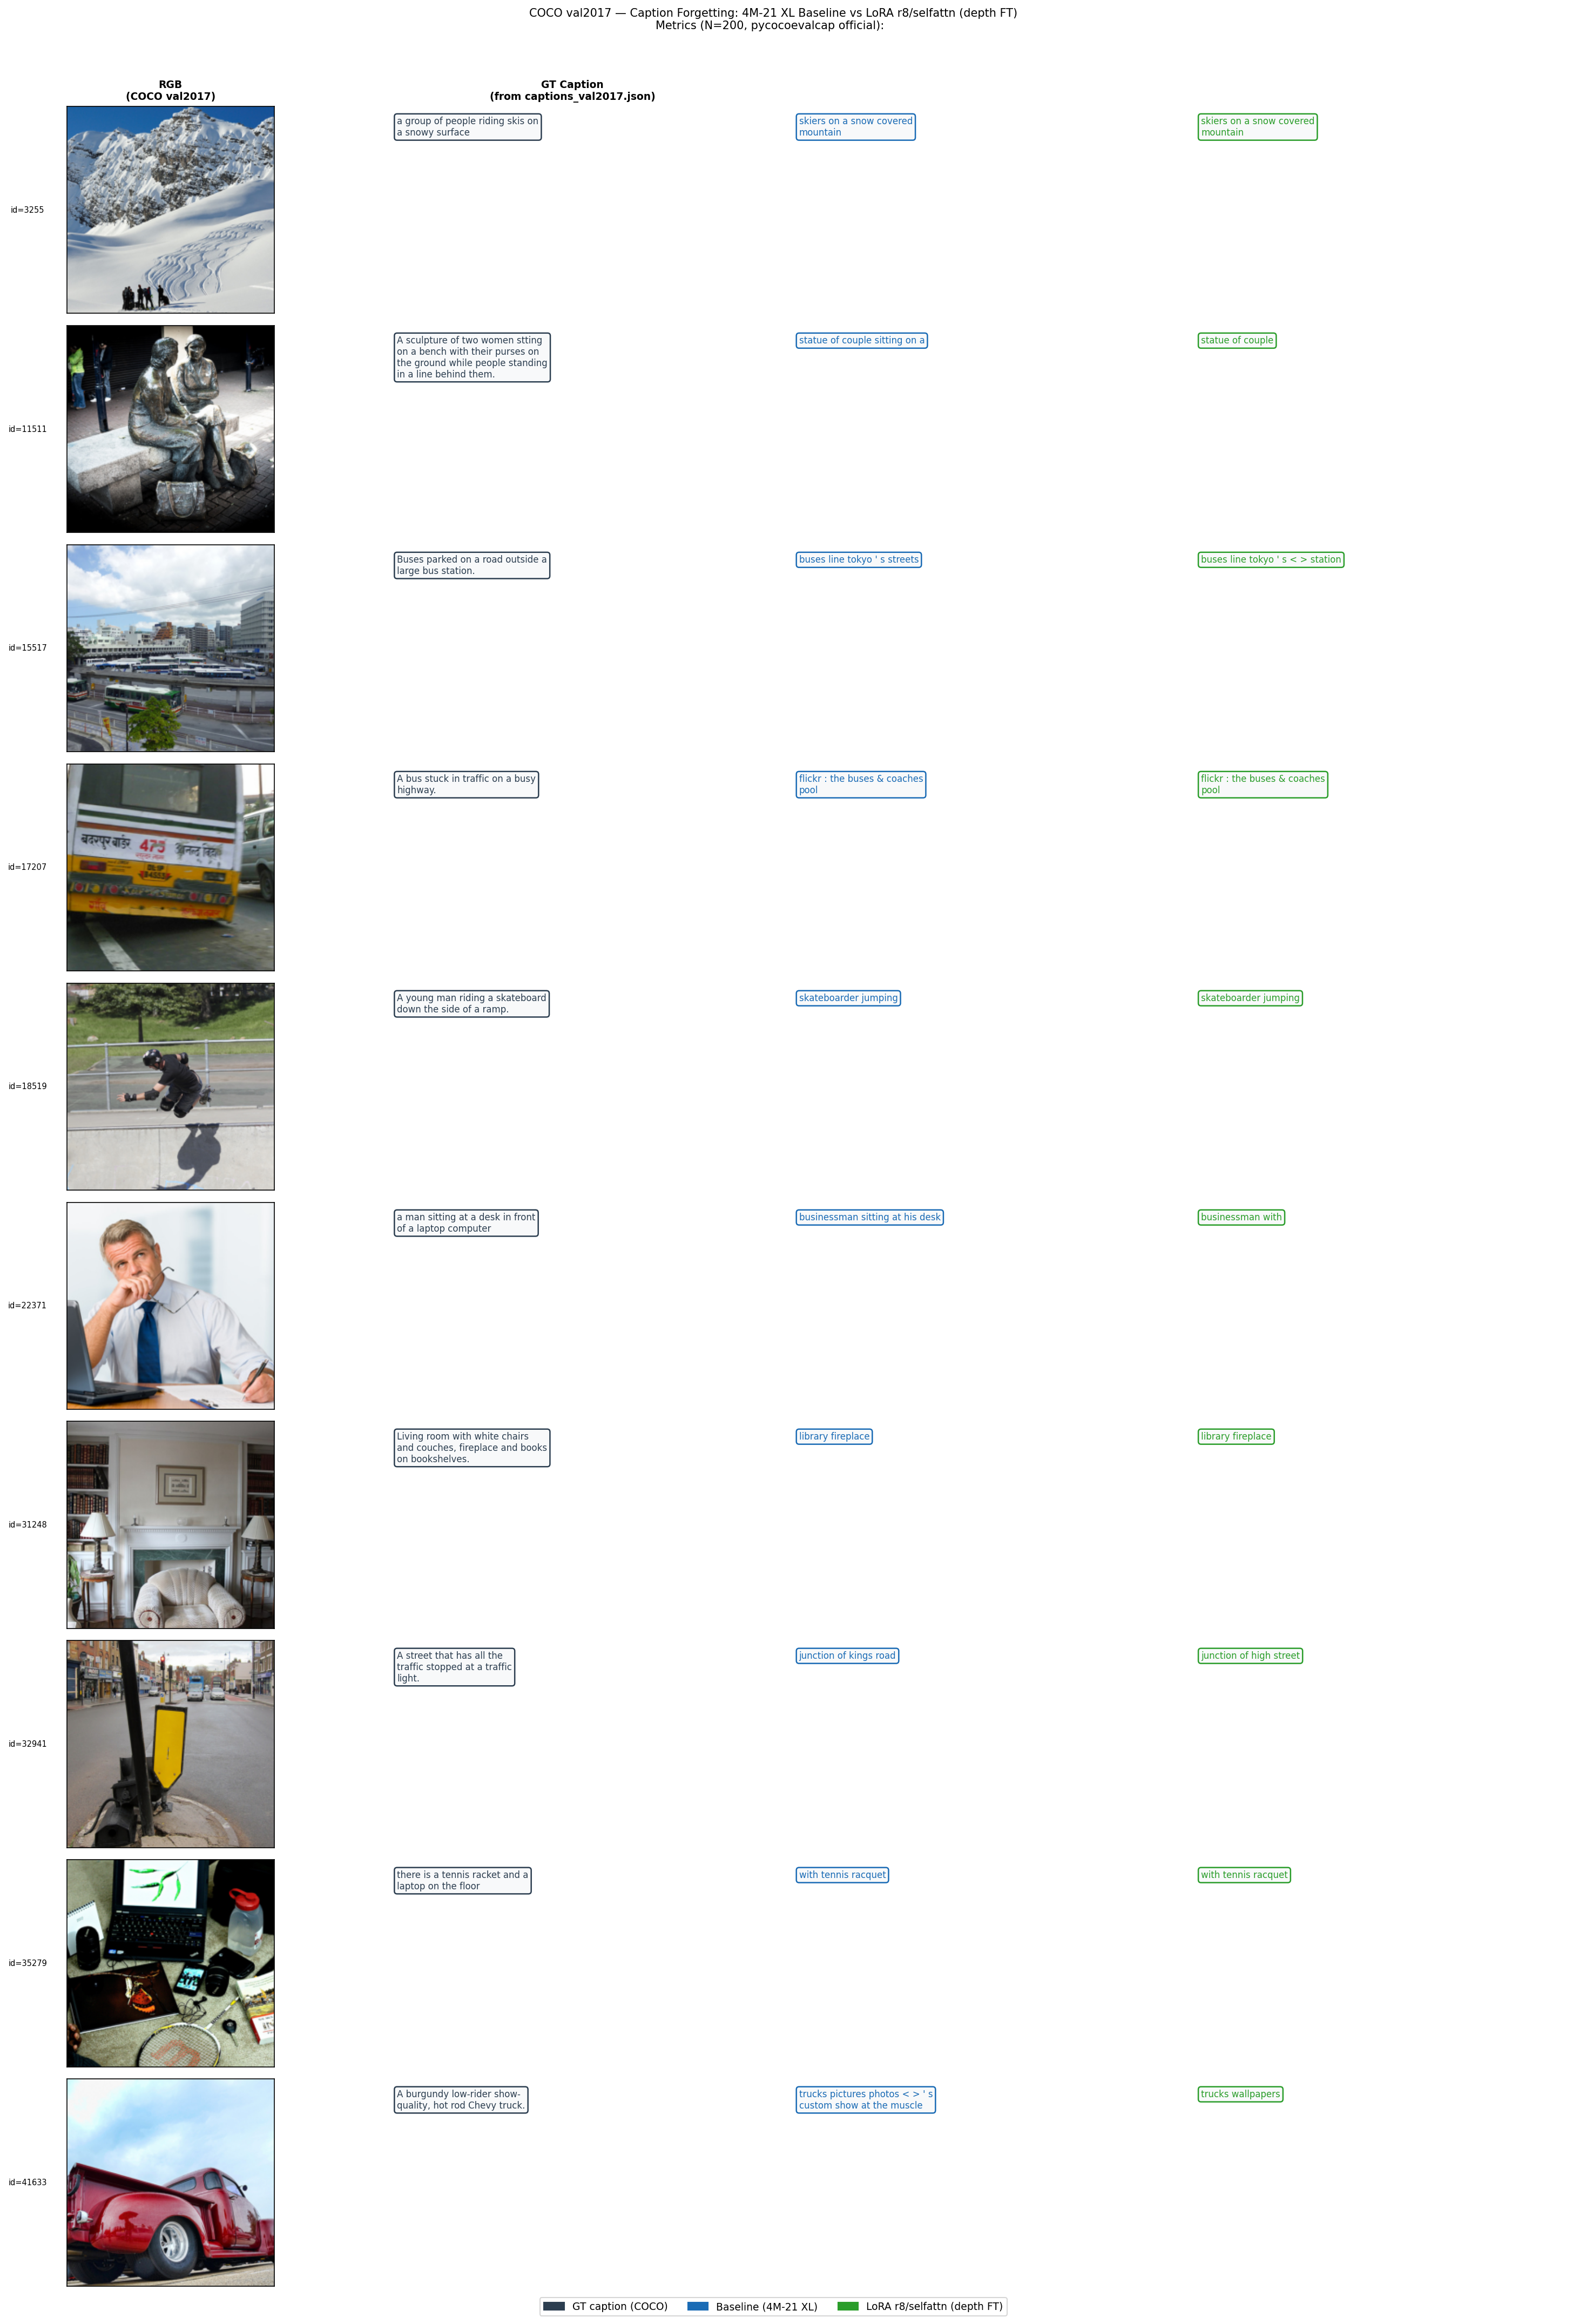

In [17]:
def wrap(text, width=28):
    """Wrap text for display in a narrow matplotlib cell."""
    return '\n'.join(textwrap.wrap(str(text), width=width))


n_rows   = N_VIZ
fig_w    = 20
fig_h    = n_rows * 2.8
fig, axes = plt.subplots(n_rows, 4, figsize=(fig_w, fig_h))

col_titles = [
    'RGB\n(COCO val2017)',
    'GT Caption\n(from captions_val2017.json)',
]
for col, title in enumerate(col_titles):
    axes[0, col].set_title(title, fontsize=9, fontweight='bold', pad=6)

for row, s in enumerate(viz_samples):
    iid = s['image_id']
    rgb_np  = load_rgb_display(s['path'])
    gt_caps = id2captions.get(iid, ['N/A'])
    gt_show = gt_caps[0]                             # show first GT caption
    cap_b   = captions_baseline.get(iid, '')
    cap_l   = captions_lora.get(iid, '')

    # Col 0: RGB image
    axes[row, 0].imshow(rgb_np)
    axes[row, 0].set_ylabel(f'id={iid}', fontsize=7, rotation=0, labelpad=35, va='center')

    # Cols 1-3: text panels
    for col, (text, color) in enumerate([
        (gt_show, '#2c3e50'),
        (cap_b,   '#1a6bb5'),
        (cap_l,   '#2a9d2a'),
    ], start=1):
        ax = axes[row, col]
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.text(0.05, 0.95, wrap(text, width=32),
                va='top', ha='left', fontsize=8,
                color=color, wrap=True,
                transform=ax.transAxes,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='#f8f9fa',
                          edgecolor=color, linewidth=1.2))
        ax.set_xticks([]); ax.set_yticks([])
        ax.spines[:].set_visible(False)

    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])

legend_patches = [
    mpatches.Patch(color='#2c3e50', label='GT caption (COCO)'),
    mpatches.Patch(color='#1a6bb5', label='Baseline (4M-21 XL)'),
    mpatches.Patch(color='#2a9d2a', label='LoRA r8/selfattn (depth FT)'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=3, fontsize=9,
           bbox_to_anchor=(0.5, -0.01))

fig.suptitle(
    f'COCO val2017 — Caption Forgetting: 4M-21 XL Baseline vs LoRA r8/selfattn (depth FT)\n'
    f'Metrics (N={len(eval_ids)}, pycocoevalcap official):  ',
    fontsize=10, y=1.01,
)
plt.tight_layout()

out_path = os.path.join(FIGURES_DIR, 'caption_forgetting_r8.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f'\nFigure saved → {out_path}')

try:
    from IPython.display import display, Image as IPImage
    display(IPImage(out_path))
except Exception:
    pass